# Vietnam Cashless Transactions 2026 — Data Audit & Exploratory Data Analysis

**Project:** AQ-FL (Adversarial Post-Quantum Federated Learning) — fraud detection across 10 simulated financial-institution clients using the Flower (`flwr`) framework with an MLP classifier.

**Purpose of this notebook:** audit and explore the dataset *before* any model code is written. Findings feed the Data Audit & EDA section of Chapter 3 of the dissertation.

**Dataset:** Kaggle dataset *hnlieu/vietnam-cashless-transactions-2026* — 2,000 rows × 8 columns (`Transaction_ID`, `Timestamp`, `User_ID`, `Amount_VND`, `Payment_Method`, `Merchant_Category`, `Location`, `Is_Fraud`).

> ## ⚠️ SYNTHETIC DATA
> The Kaggle page explicitly labels this dataset as **"Synthetic data for cashless payment trends and fraud detection in Vietnam 2026."** No real transactions or data subjects are represented. In this project it serves **only as a distributional generalisation probe** — testing whether the FL pipeline handles a different schema, currency scale, and categorical encoding — and **not** as real-world validation of the Vietnamese market. Every conclusion drawn below reflects the generator's assumptions, not organic fraud behaviour.

**Contents**
1. Dataset Overview
2. Structural Audit (Phase 1)
3. Class Balance Analysis
4. Univariate EDA (Amount_VND, Timestamp, categoricals, User_ID)
5. Fraud-Stratified Analysis
6. Outlier Analysis
7. FL Partitioning Analysis (Dirichlet)
8. Data Card (Gebru et al. 2021)

### Environment setup

Install the required packages (no-op if already installed). Audit/EDA only: pandas, matplotlib, seaborn.

In [1]:
%pip install -q pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

In [3]:
import sys
print(f"Python {sys.version.split()[0]}")
print(f"numpy {np.__version__} | pandas {pd.__version__}")
import matplotlib
print(f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.9
numpy 2.3.5 | pandas 2.3.3
matplotlib 3.10.6 | seaborn 0.13.2


In [4]:
DATA_PATH = Path("../Data/Vietnam_Cashless_Transactions_2026/vn_cashless_2026.csv")
assert DATA_PATH.exists(), "Data file not found - check DATA_PATH"

## 1. Dataset Overview

In [5]:
vn = pd.read_csv(DATA_PATH)
print(f"Shape: {vn.shape[0]:,} rows x {vn.shape[1]} columns")
print(vn.dtypes.to_string())

Shape: 2,000 rows x 8 columns
Transaction_ID       object
Timestamp            object
User_ID              object
Amount_VND            int64
Payment_Method       object
Merchant_Category    object
Location             object
Is_Fraud              int64


In [6]:
vn.head()

,Transaction_ID,Timestamp,User_ID,Amount_VND,Payment_Method,Merchant_Category,Location,Is_Fraud
0,TXN20260000,2026-01-06 07:43:24.286652,USER_436,1685255,E-Wallet,Transport,Đà Nẵng,0
1,TXN20260001,2026-03-19 17:48:09.431230,USER_240,2586984,QR Code,Utilities,Hải Phòng,0
2,TXN20260002,2025-06-11 08:56:05.556205,USER_312,4224431,Credit Card,Food & Beverage,Hà Nội,0
3,TXN20260003,2026-03-12 11:58:58.523311,USER_270,390853,E-Wallet,Utilities,Hải Phòng,0
4,TXN20260004,2025-09-12 21:40:56.081134,USER_253,3330817,Credit Card,Supermarket,Đà Nẵng,0


In [7]:
vn.tail()

,Transaction_ID,Timestamp,User_ID,Amount_VND,Payment_Method,Merchant_Category,Location,Is_Fraud
1995,TXN20261995,2025-09-12 13:14:36.188232,USER_176,2681350,Napas Card,Utilities,Hà Nội,0
1996,TXN20261996,2025-09-17 02:19:34.183392,USER_128,4811944,Napas Card,Utilities,Cần Thơ,1
1997,TXN20261997,2025-05-14 23:29:12.308543,USER_459,1960764,Credit Card,Shopping,Cần Thơ,0
1998,TXN20261998,2025-08-31 03:31:43.956125,USER_132,1967513,E-Wallet,Shopping,TP.HCM,0
1999,TXN20261999,2026-03-22 01:06:56.328003,USER_250,911946,QR Code,Shopping,Hải Phòng,0


The schema is deliberately simple: one row per transaction, one identifier each for transaction and user, a VND amount, three categorical descriptors, a timestamp, and a binary fraud label.

## 2. Structural Audit (Phase 1)

In [8]:
null_counts = vn.isna().sum()
print("Null counts per column:")
print(null_counts.to_string())
print(f"\nTotal nulls: {int(null_counts.sum())} (expected 0 for synthetic data)")

Null counts per column:
Transaction_ID       0
Timestamp            0
User_ID              0
Amount_VND           0
Payment_Method       0
Merchant_Category    0
Location             0
Is_Fraud             0

Total nulls: 0 (expected 0 for synthetic data)


In [9]:
print("Full-row duplicates:", int(vn.duplicated().sum()))
print("Duplicate Transaction_ID:", int(vn["Transaction_ID"].duplicated().sum()))

Full-row duplicates: 0
Duplicate Transaction_ID: 0


In [10]:
vn["Timestamp"] = pd.to_datetime(vn["Timestamp"], errors="raise")
print("Timestamp parsed as:", vn["Timestamp"].dtype)
print(f"Range: {vn['Timestamp'].min()} to {vn['Timestamp'].max()}")

Timestamp parsed as: datetime64[ns]
Range: 2025-03-25 11:05:08.720912 to 2026-03-25 15:32:24.440464


No nulls and no duplicate rows or transaction IDs — consistent with clean synthetic generation. `Timestamp` parses without error into a proper datetime dtype, and there are no dtype anomalies; the audit surface of this dataset is minimal compared with IEEE-CIS.

## 3. Class Balance Analysis

In [11]:
counts = vn["Is_Fraud"].value_counts().sort_index()
pct = vn["Is_Fraud"].value_counts(normalize=True).sort_index() * 100
balance = pd.DataFrame({"count": counts.values, "percent": pct.round(2).values},
                       index=["Legitimate (0)", "Fraud (1)"])
balance

,count,percent
Legitimate (0),1921,96.05
Fraud (1),79,3.95


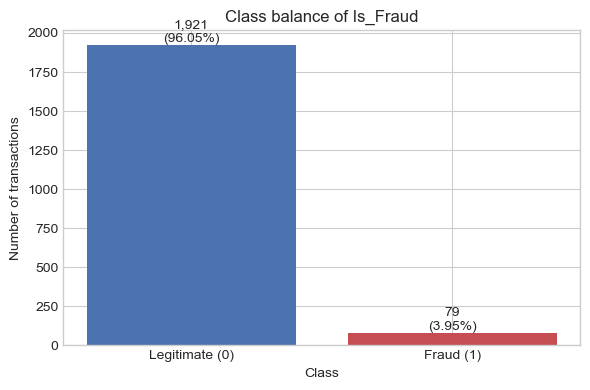

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(balance.index, balance["count"], color=["#4C72B0", "#C44E52"])
for i, (n, p) in enumerate(zip(balance["count"], balance["percent"])):
    ax.text(i, n, f"{n:,}\n({p:.2f}%)", ha="center", va="bottom")
ax.set_title("Class balance of Is_Fraud")
ax.set_xlabel("Class")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

The fraud rate sits near 3.95% — strikingly close to IEEE-CIS's ~3.5%. Given the synthetic origin, this is most plausibly a **generation parameter** chosen to imitate realistic fraud prevalence rather than an empirical property of Vietnamese payments.

**Key Findings — Section 3**
- The label is imbalanced at ~3.95% fraud (~79 positive cases in total).
- The similarity to the IEEE-CIS fraud rate likely reflects a deliberate generator setting.
- With so few positives overall, per-client positive counts in FL will be extremely sparse (quantified in Section 7).

## 4. Univariate EDA

### 4.1 Amount_VND

In [13]:
amt = vn["Amount_VND"]
amt.describe().to_frame("Amount_VND")

,Amount_VND
count,2.000000e+03
mean,2.491037e+06
std,1.406125e+06
min,2.101100e+04
25%,1.317840e+06
50%,2.450768e+06
75%,3.645887e+06
max,4.994053e+06


In [14]:
pearson_skew = 3 * (amt.mean() - amt.median()) / amt.std()
print(f"Mean: {amt.mean():,.0f} VND | Median: {amt.median():,.0f} VND | SD: {amt.std():,.0f} VND")
print(f"Pearson's skewness coefficient (3*(mean-median)/std): {pearson_skew:.3f}")

Mean: 2,491,037 VND | Median: 2,450,768 VND | SD: 1,406,125 VND
Pearson's skewness coefficient (3*(mean-median)/std): 0.086


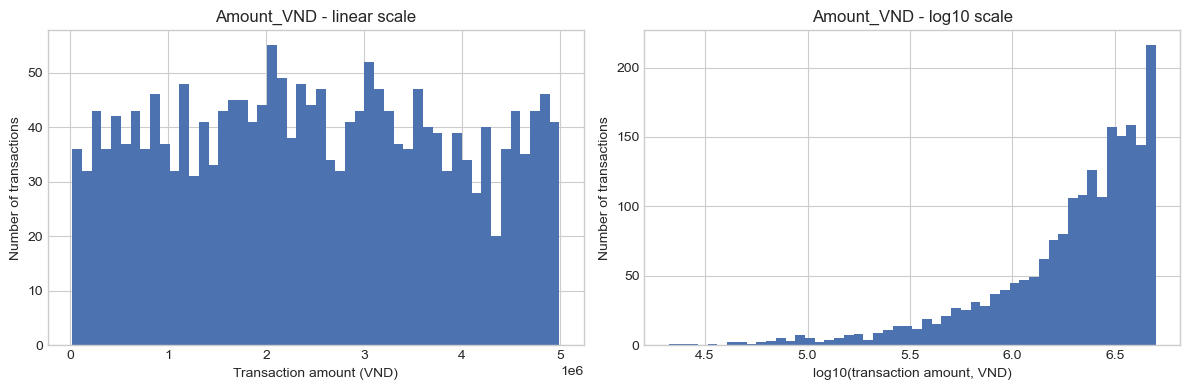

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(amt, bins=50, color="#4C72B0")
axes[0].set_title("Amount_VND - linear scale")
axes[0].set_xlabel("Transaction amount (VND)")
axes[0].set_ylabel("Number of transactions")
axes[1].hist(np.log10(amt[amt > 0]), bins=50, color="#4C72B0")
axes[1].set_title("Amount_VND - log10 scale")
axes[1].set_xlabel("log10(transaction amount, VND)")
axes[1].set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

The linear-scale histogram is near-uniform between roughly 21K and 5M VND with a visible hard ceiling — a synthetic signature entirely unlike the log-normal shape of real transaction amounts (compare IEEE-CIS).

### 4.2 Timestamp

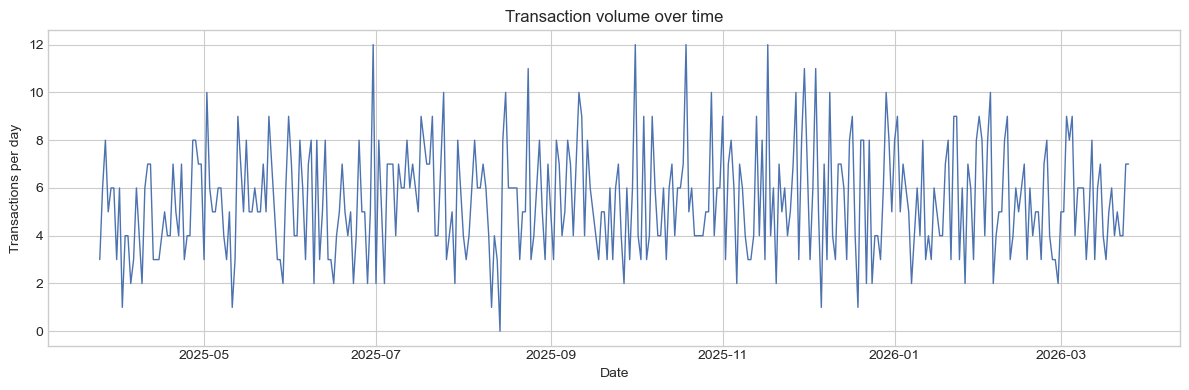

In [16]:
daily_volume = vn.set_index("Timestamp").resample("D").size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_volume.index, daily_volume.values, color="#4C72B0", lw=1)
ax.set_title("Transaction volume over time")
ax.set_xlabel("Date")
ax.set_ylabel("Transactions per day")
plt.tight_layout()
plt.show()

Daily volume is approximately uniform across the covered period, without the weekly periodicity or seasonal spikes of real payment data — another synthetic signature.

### 4.3 Categorical features

In [17]:
for col in ["Payment_Method", "Merchant_Category", "Location"]:
    freq = vn[col].value_counts()
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": freq, "percent": (freq / len(vn) * 100).round(2)}).to_string(), "\n")

--- Payment_Method ---
                count  percent
Payment_Method                
QR Code           527    26.35
Credit Card       519    25.95
E-Wallet          504    25.20
Napas Card        450    22.50 

--- Merchant_Category ---
                   count  percent
Merchant_Category                
Shopping             429    21.45
Supermarket          427    21.35
Transport            406    20.30
Utilities            379    18.95
Food & Beverage      359    17.95 

--- Location ---
           count  percent
Location                 
TP.HCM       433    21.65
Cần Thơ      422    21.10
Hải Phòng    392    19.60
Đà Nẵng      380    19.00
Hà Nội       373    18.65 



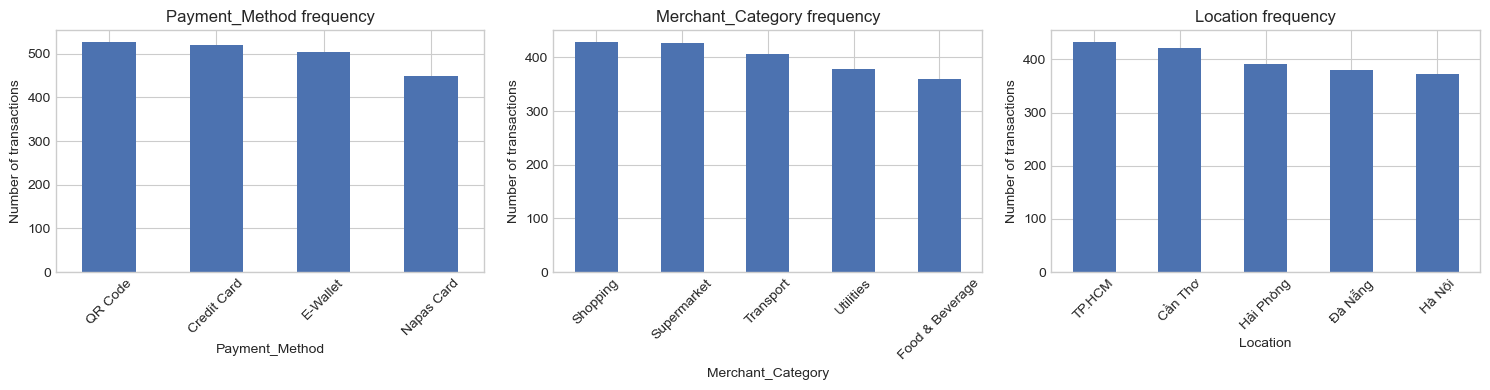

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Payment_Method", "Merchant_Category", "Location"]):
    vn[col].value_counts().plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(f"{col} frequency")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of transactions")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

All three categoricals are split near-uniformly (4 payment methods, 5 merchant categories, 5 Vietnamese cities) — real payment ecosystems are never this balanced, confirming uniform random generation.

### 4.4 User_ID

In [19]:
txn_per_user = vn.groupby("User_ID").size()
print(f"Unique users: {vn['User_ID'].nunique():,}")
print(f"Transactions per user - mean: {txn_per_user.mean():.2f}, "
      f"min: {txn_per_user.min()}, max: {txn_per_user.max()}")
txn_per_user.describe().to_frame("txns_per_user")

Unique users: 397
Transactions per user - mean: 5.04, min: 1, max: 14


,txns_per_user
count,397.000000
mean,5.037783
std,2.240825
min,1.000000
25%,3.000000
50%,5.000000
75%,6.000000
max,14.000000


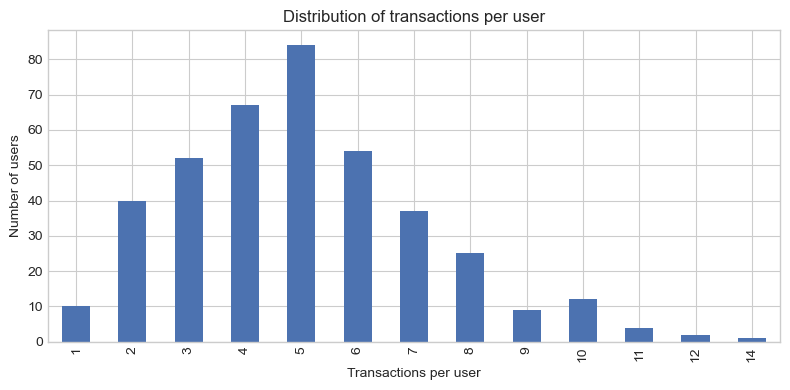

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
txn_per_user.value_counts().sort_index().plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Distribution of transactions per user")
ax.set_xlabel("Transactions per user")
ax.set_ylabel("Number of users")
plt.tight_layout()
plt.show()

Users average roughly five transactions each with a narrow spread — consistent with uniform assignment of transactions to users rather than realistic heavy-tailed user activity.

**Key Findings — Section 4**
- `Amount_VND` is near-uniform between ~21K and ~5M VND with a hard ceiling — a synthetic distribution, with skewness near zero.
- Temporal volume and all three categorical features are near-uniform, lacking the periodicity and concentration of real payment data.
- ~400 users average ~5 transactions each with little dispersion, again reflecting the generator's uniform design.

## 5. Fraud-Stratified Analysis

> **Caveat (stated up front):** because the data are synthetic, any association between features and `Is_Fraud` reflects the **generator's assumptions**, not organic fraud behaviour. These plots characterise the generator, not Vietnamese payments.

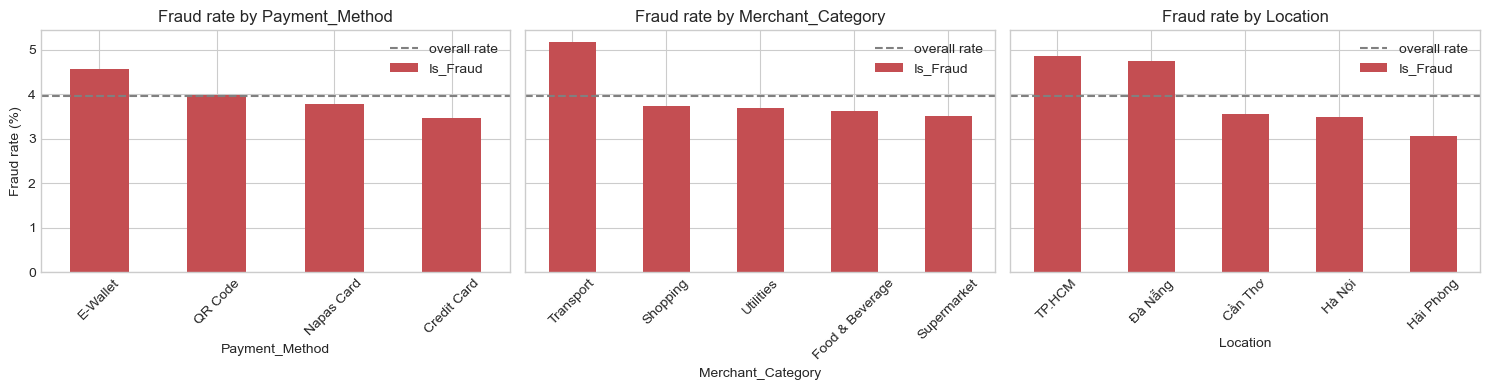

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
overall = vn["Is_Fraud"].mean() * 100
for ax, col in zip(axes, ["Payment_Method", "Merchant_Category", "Location"]):
    rates = vn.groupby(col)["Is_Fraud"].mean().sort_values(ascending=False) * 100
    rates.plot.bar(ax=ax, color="#C44E52")
    ax.axhline(overall, color="gray", ls="--", label="overall rate")
    ax.set_title(f"Fraud rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fraud rate (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

Fraud rates fluctuate around the ~4% baseline across all three categoricals; with only ~79 positives in total, each category cell contains very few fraud cases, so apparent differences are dominated by sampling noise.

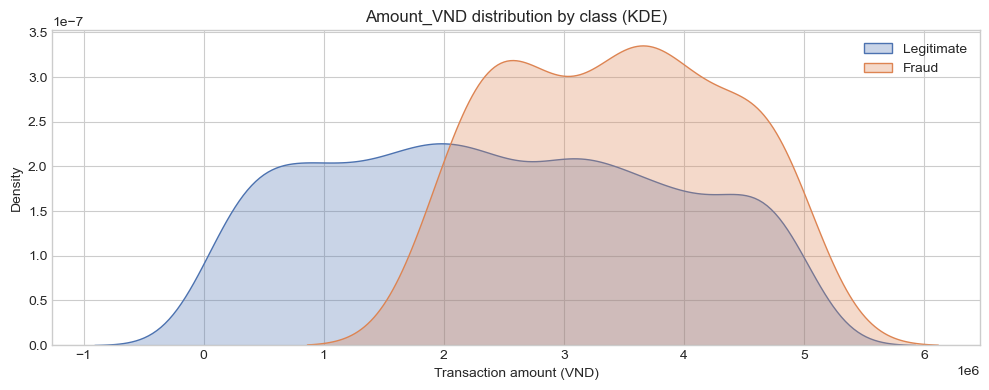

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(vn.loc[vn["Is_Fraud"] == 0, "Amount_VND"], ax=ax, label="Legitimate", fill=True, alpha=0.3)
sns.kdeplot(vn.loc[vn["Is_Fraud"] == 1, "Amount_VND"], ax=ax, label="Fraud", fill=True, alpha=0.3)
ax.set_title("Amount_VND distribution by class (KDE)")
ax.set_xlabel("Transaction amount (VND)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

The class-conditional amount distributions are near-identical, suggesting the generator assigned fraud labels (near-)independently of amount.

**Key Findings — Section 5**
- Feature–fraud associations are weak and noise-dominated given only ~79 positive cases.
- Any associations that do appear encode generator assumptions, not real fraud patterns — flagged explicitly for the dissertation.
- The dataset cannot support substantive fraud-signal analysis; its value lies in schema and distribution diversity for the FL pipeline.

## 6. Outlier Analysis

In [23]:
mu, sigma = amt.mean(), amt.std()
threshold = mu + 3 * sigma
outliers = vn[amt > threshold]
print(f"Mean: {mu:,.0f} VND | SD: {sigma:,.0f} VND | +3 SD threshold: {threshold:,.0f} VND")
print(f"Transactions above +3 SD: {len(outliers)}")
print(f"Maximum observed Amount_VND: {amt.max():,.0f} VND (hard ceiling check)")

Mean: 2,491,037 VND | SD: 1,406,125 VND | +3 SD threshold: 6,709,411 VND
Transactions above +3 SD: 0
Maximum observed Amount_VND: 4,994,053 VND (hard ceiling check)


Because the distribution is near-uniform with a hard ceiling around 5,000,000 VND, the +3 SD threshold lies beyond the maximum and no (or almost no) outliers exist — further confirmation of bounded synthetic generation. The absence of a heavy tail contrasts sharply with IEEE-CIS and real monetary data, and no outlier handling is required for this dataset.

## 7. FL Partitioning Analysis

2,000 rows across **10 clients** — 200 rows per client on average, an extreme small-data regime for federated learning. The same Dirichlet label-skew scheme used in the IEEE-CIS audit (Hsu et al., 2019, arXiv:1909.06335) is characterised here.

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
N_CLIENTS = 10

def dirichlet_partition(labels, n_clients, alpha, rng):
    assignment = np.empty(len(labels), dtype=int)
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        props = rng.dirichlet(np.full(n_clients, alpha))
        cuts = (np.cumsum(props[:-1]) * len(idx)).astype(int)
        for k, part in enumerate(np.split(idx, cuts)):
            assignment[part] = k
    return assignment

def client_stats(labels, assignment):
    stats = (pd.DataFrame({"client": assignment, "label": labels})
             .groupby("client")["label"]
             .agg(rows="size", fraud_count="sum", fraud_rate="mean"))
    stats["fraud_rate_pct"] = (stats["fraud_rate"] * 100).round(3)
    return stats

In [25]:
labels = vn["Is_Fraud"].to_numpy()
alphas = [100.0, 1.0, 0.5]
partitions = {a: client_stats(labels, dirichlet_partition(labels, N_CLIENTS, a, rng))
              for a in alphas}
comparison = pd.concat({f"alpha={a}": partitions[a][["rows", "fraud_count", "fraud_rate_pct"]]
                        for a in alphas}, axis=1)
comparison

alpha=100.0                            alpha=1.0              \
              rows fraud_count fraud_rate_pct      rows fraud_count   
client                                                                
0              214           7          3.271       138           9   
1              185           8          4.324       156          15   
2              207           9          4.348        31           1   
3              200           9          4.500       301           7   
4              227           7          3.084        18           4   
5              197           7          3.553       197           2   
6              214           8          3.738       667          10   
7              181           7          3.867       248           5   
8              164           8          4.878       148          11   
9              211           9          4.265        96          15   

                      alpha=0.5                             
       fraud_rate_pct      rows fraud_count fraud_rate_pct  
client                                                      
0               6.522      63.0        11.0         17.460  
1               9.615      96.0        25.0         26.042  
2               3.226     340.0         6.0          1.765  
3               2.326     116.0         2.0          1.724  
4              22.222       NaN         NaN            NaN  
5               1.015      97.0        22.0         22.680  
6               1.499     827.0         0.0          0.000  
7               2.016     232.0         7.0          3.017  
8               7.432     101.0         0.0          0.000  
9              15.625     128.0         6.0          4.688

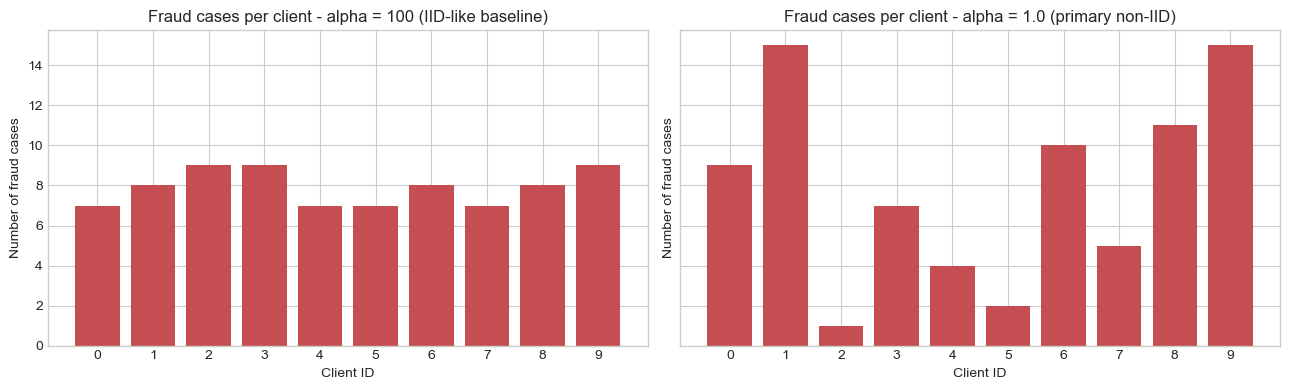

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, a, name in [(axes[0], 100.0, "alpha = 100 (IID-like baseline)"),
                    (axes[1], 1.0, "alpha = 1.0 (primary non-IID)")]:
    stats = partitions[a]
    ax.bar(stats.index.astype(str), stats["fraud_count"], color="#C44E52")
    ax.set_title(f"Fraud cases per client - {name}")
    ax.set_xlabel("Client ID")
    ax.set_ylabel("Number of fraud cases")
plt.tight_layout()
plt.show()

At $\alpha = 100$ each client receives roughly 200 rows and about 8 fraud cases. Under the primary condition $\alpha = 1.0$ both counts skew moderately; at the $\alpha = 0.5$ stress setting some clients fall to zero positives. Conditions match the IEEE-CIS audit ($\alpha = 100$ baseline, $\alpha = 1.0$ primary, $\alpha = 0.5$ stress) so results are comparable across the two datasets.

> **Known limitation (flagged for the FL experiment):** with single-digit — and under skewed partitions sometimes zero — positive cases per client, per-client gradient signal for the fraud class is extremely sparse and per-client AUC estimates will be unstable. This dataset cannot support robust FL training on its own; it functions as a stress test of pipeline behaviour under label sparsity and as a schema-diversity probe alongside IEEE-CIS.

*Working note: 10 clients was kept rather than reduced to 4 or 5 purely so the client count matches the IEEE-CIS experiment — the sparsity that results is accepted and recorded above rather than engineered away.*

**Key Findings — Section 7**
- Under the Dirichlet scheme the 10 clients average 200 rows each; even the IID-like condition leaves only ~8 fraud cases per client.
- The same three $\alpha$ conditions as IEEE-CIS are used, so cross-dataset comparison holds.
- Extreme per-client label sparsity is recorded as a known limitation of this dataset for FL training.

## 8. Data Card — Vietnam Cashless Transactions 2026

*Format follows Gebru et al. (2021), "Datasheets for Datasets."*

**Motivation.** A synthetic proxy dataset for the Vietnamese cashless-payment ecosystem, used in this project to supplement IEEE-CIS with a Southeast Asian financial context and a structurally different schema.

**Composition.** 2,000 synthetic transactions × 8 features: transaction and user identifiers, timestamp, amount in VND, payment method (4 values), merchant category (5 values), location (5 Vietnamese cities), and a binary fraud label (~3.95% positive).

**Collection & Curation.** Synthetically generated; the Kaggle page explicitly describes it as "Synthetic data for cashless payment trends and fraud detection in Vietnam 2026." No real transactions were collected and no data subjects are affected.

**Preprocessing applied (this notebook).** None — audit and EDA only (timestamp parsing for analysis; no imputation, encoding, or feature engineering).

**Known limitations.** The synthetic distribution does not reflect real fraud patterns; near-uniform categorical and amount distributions are unrealistic; the feature set is thin (no device, card, or identity features); at an average of 200 rows per client, the data are too sparse for robust FL training on their own.

**Intended use.** Generalisation probe and schema-diversity test for the AQ-FL pipeline — **not** a primary benchmark and **not** evidence about the real Vietnamese market.

**Distribution & Maintenance.** Distributed via Kaggle (`hnlieu/vietnam-cashless-transactions-2026`); static, with no updates expected.

**Distribution & usage rights.** Publicly distributed through Kaggle; used here for non-commercial academic research consistent with the licence stated on the dataset page.